In [2]:
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
import plotly.express as px

torch.__version__

'2.7.1+cu118'

In [3]:
# Create secure way of loading data
DATA_PATH = Path("enriched_data")
DATA_PATH.mkdir(parents=True,
                exist_ok=True)

DATA_NAME = "dataset_temps_elev_emis_1971-2023"
DATA_FULL_PATH = DATA_PATH / DATA_NAME

# Load and preview dataset
dataset = xr.open_dataset(DATA_FULL_PATH)
print(dataset)

<xarray.Dataset> Size: 385MB
Dimensions:      (time: 53, lat: 360, lon: 720)
Coordinates:
  * time         (time) datetime64[ns] 424B 1971-01-01 1972-01-01 ... 2023-01-01
  * lon          (lon) float32 3kB -179.8 -179.2 -178.8 ... 178.8 179.2 179.8
  * lat          (lat) float32 1kB -89.75 -89.25 -88.75 ... 88.75 89.25 89.75
Data variables:
    emissions    (time, lat, lon) float32 55MB ...
    tmp          (time, lat, lon) float32 55MB ...
    stn          (time, lat, lon) float64 110MB ...
    mae          (time, lat, lon) float32 55MB ...
    maea         (time, lat, lon) float32 55MB ...
    tmp_anomaly  (time, lat, lon) float32 55MB ...
    elev         (lat, lon) int16 518kB ...
Attributes:
    regrid_method:  conservative


In [4]:
dataframe = dataset.to_dataframe().reset_index()
dataframe.head()

,time,lat,lon,emissions,tmp,stn,mae,maea,tmp_anomaly,elev
0,1971-01-01,-89.75,-179.75,0.0,NaN,NaN,NaN,NaN,NaN,2783
1,1971-01-01,-89.75,-179.25,0.0,NaN,NaN,NaN,NaN,NaN,2783
2,1971-01-01,-89.75,-178.75,0.0,NaN,NaN,NaN,NaN,NaN,2782
3,1971-01-01,-89.75,-178.25,0.0,NaN,NaN,NaN,NaN,NaN,2782
4,1971-01-01,-89.75,-177.75,0.0,NaN,NaN,NaN,NaN,NaN,2782


In [5]:
dataframe.dropna(inplace=True)
dataframe.tail()

,time,lat,lon,emissions,tmp,stn,mae,maea,tmp_anomaly,elev
13728538,2023-01-01,83.75,-30.75,19.958090,-18.258333,1.833333,2.603,0.499,0.584721,-110
13728539,2023-01-01,83.75,-30.25,19.998077,-17.541666,1.833333,2.583,0.482,0.591820,-125
13728540,2023-01-01,83.75,-29.75,21.084202,-16.708334,1.833333,2.561,0.461,0.605094,-143
13728541,2023-01-01,83.75,-29.25,20.667263,-17.341665,1.833333,2.545,0.445,0.606634,-172
13728542,2023-01-01,83.75,-28.75,20.708178,-16.008333,1.833333,2.524,0.426,0.611882,-199


In [6]:
def animated_plots(df, color: str):
    """Create animated plot showing the change of variable from 1971 till 2023"""
    """Resource heavy!"""
    fig = px.scatter_geo(
        df,
        lat=df['lat'], lon=df['lon'],
        animation_frame="time",
        color=color,
        color_continuous_scale='RdBu_r',
        projection='natural earth',
        title=f"Global {color} change {df['time'].min().strftime('%Y')} - {df['time'].max().strftime('%Y')}"
    
    )
    
    return fig.show()

In [7]:
# animated_plots(dataframe, "tmp") 

In [8]:
dataset.data_vars

Data variables:
    emissions    (time, lat, lon) float32 55MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    tmp          (time, lat, lon) float32 55MB nan nan nan nan ... nan nan nan
    stn          (time, lat, lon) float64 110MB nan nan nan nan ... nan nan nan
    mae          (time, lat, lon) float32 55MB nan nan nan nan ... nan nan nan
    maea         (time, lat, lon) float32 55MB nan nan nan nan ... nan nan nan
    tmp_anomaly  (time, lat, lon) float32 55MB nan nan nan nan ... nan nan nan
    elev         (lat, lon) int16 518kB 2783 2783 2782 ... -4182 -4177 -4172

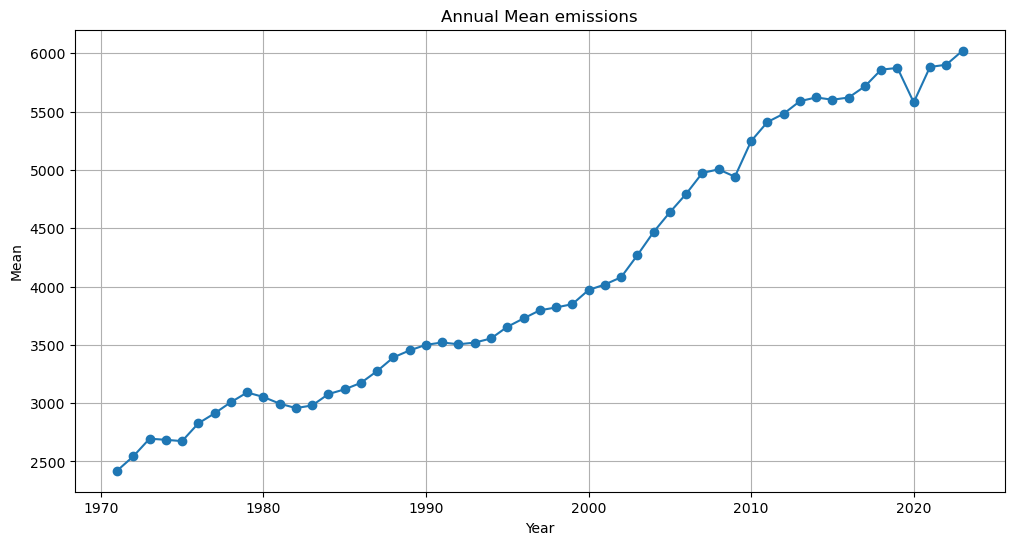

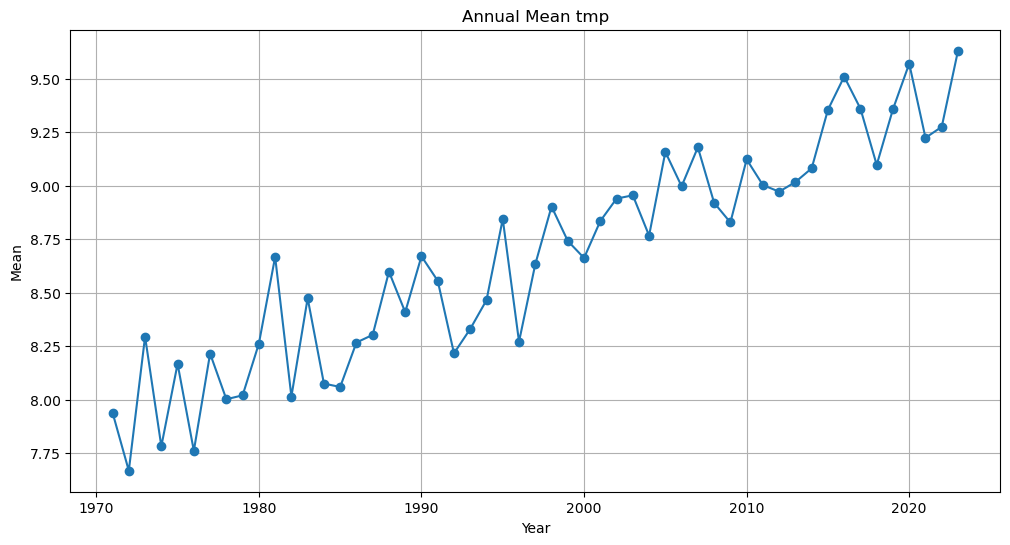

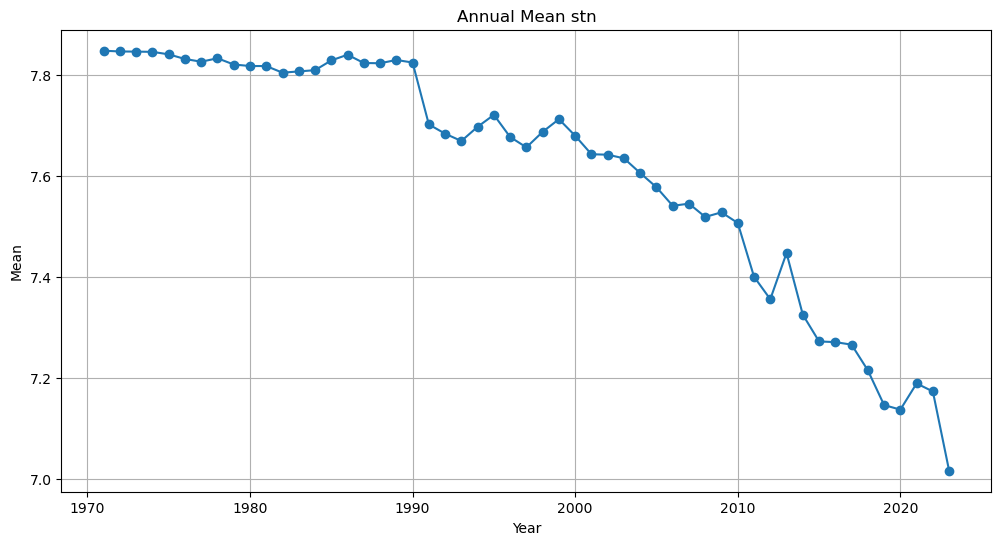

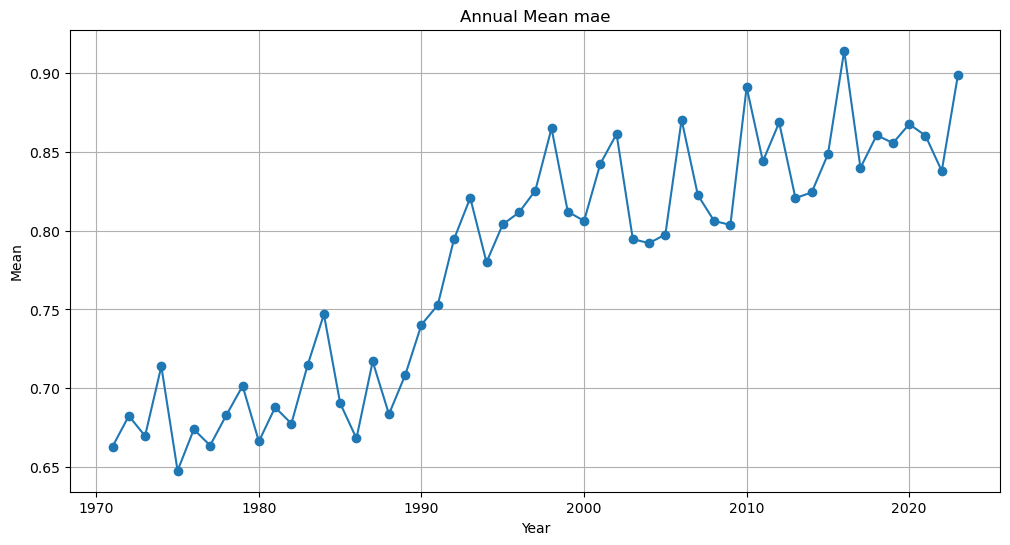

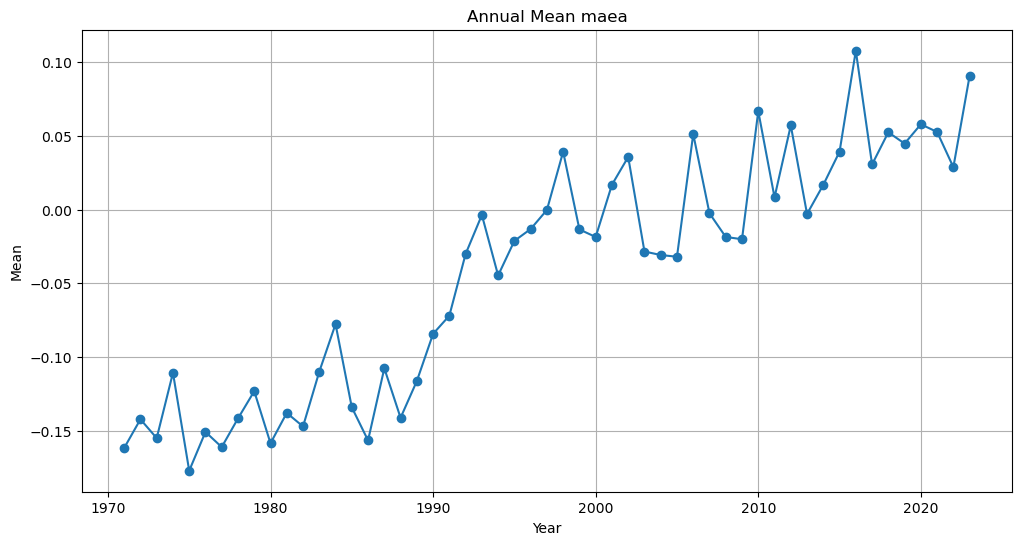

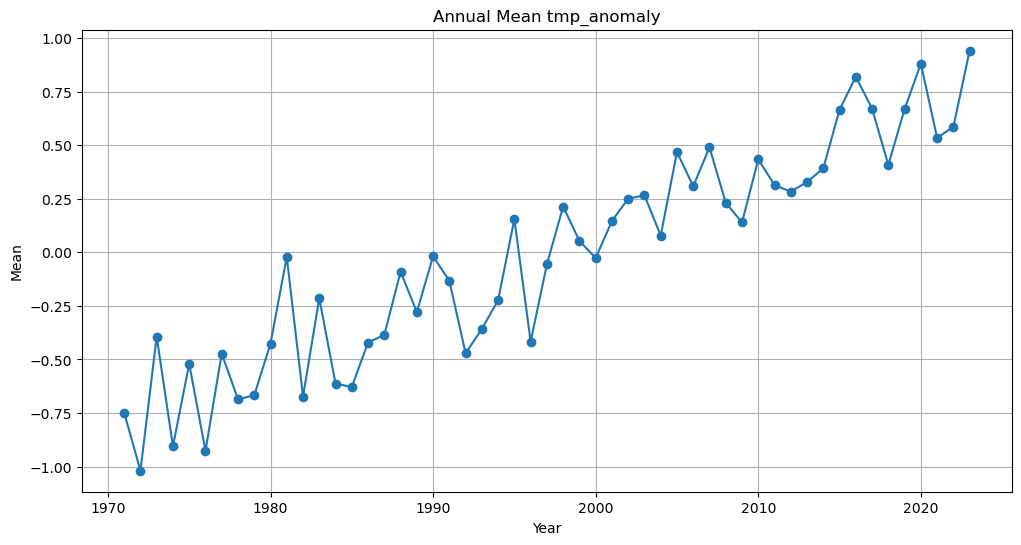

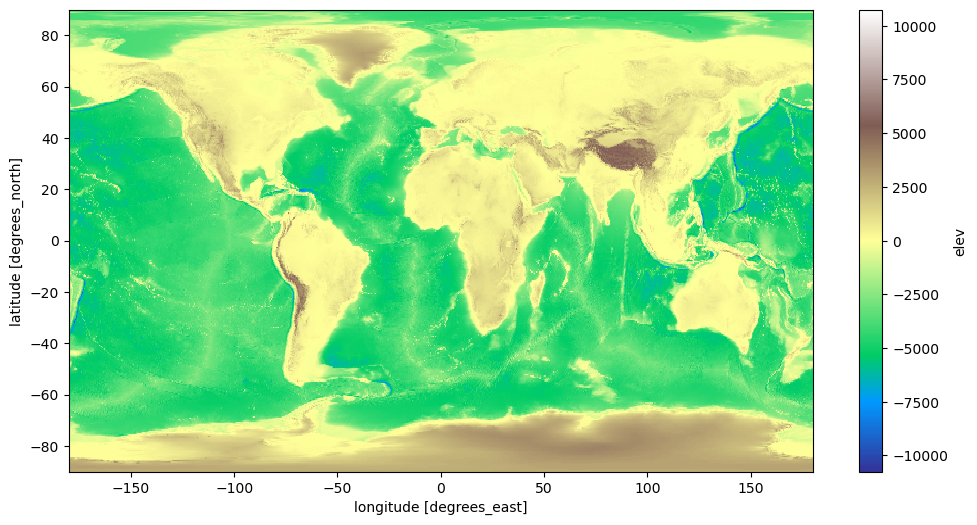

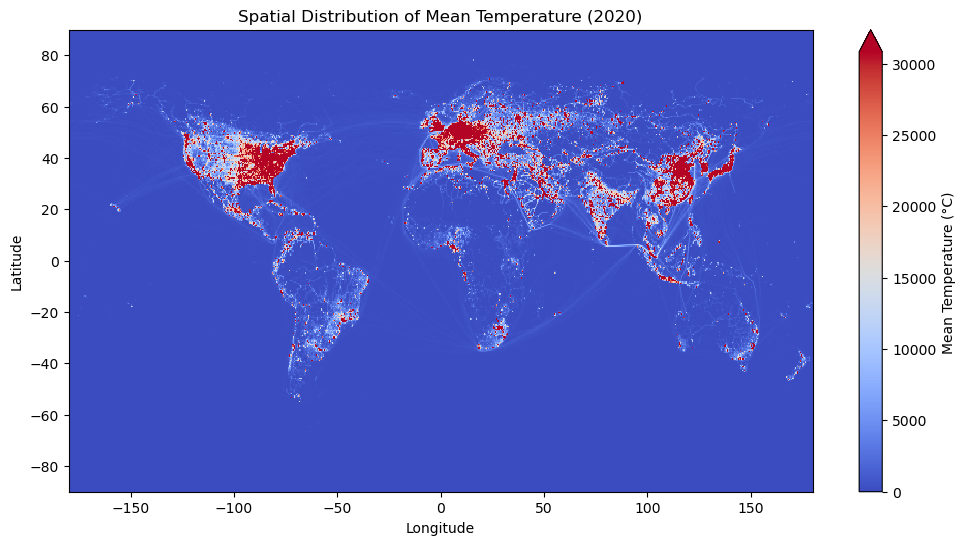

In [ ]:
# Explore the data using plots

for var in list(dataset.data_vars):
    if not var == 'elev':
        # Yearly means for all features
        annual_means = dataset[var].groupby('time.year').mean(dim=['time', 'lat', 'lon'])
        plt.figure(figsize=(12,6))
        annual_means.plot(marker='o')
        plt.title(f"Annual {var}")
        plt.xlabel('Year')
        plt.ylabel('Mean')
        plt.grid(True)
        plt.show()
    else:
        elev = dataset['elev']
        elev.plot(cmap='terrain', x='lon', y='lat', figsize=(12, 6))
        plt.show()

# Select year 
year = 2020
ds_year = dataset.sel(time=str(year))

# Yearly means for easier plotting
mean_emis_year = dataset['emissions'].mean(dim='time')  # shape: (lat, lon)

# Plot using matplotlib
plt.figure(figsize=(12, 6))
mean_emis_year.plot(
    cmap="coolwarm",
    robust=True,
    cbar_kwargs={'label': 'Mean Temperature (°C)'}
)
plt.title(f"Spatial Distribution of Mean Temperature ({year})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()




In [18]:
dataset.emissions

<xarray.DataArray 'emissions' (time: 53, lat: 360, lon: 720)> Size: 55MB
array([[[0.      , 0.      , ..., 0.      , 0.      ],
        [0.      , 0.      , ..., 0.      , 0.      ],
        ...,
        [0.      , 0.      , ..., 0.      , 0.      ],
        [0.      , 0.      , ..., 0.      , 0.      ]],

       [[0.      , 0.      , ..., 0.      , 0.      ],
        [0.      , 0.      , ..., 0.      , 0.      ],
        ...,
        [0.      , 0.      , ..., 0.      , 0.      ],
        [0.      , 0.      , ..., 0.      , 0.      ]],

       ...,

       [[0.      , 0.      , ..., 0.      , 0.      ],
        [0.      , 0.      , ..., 0.      , 0.      ],
        ...,
        [0.      , 0.      , ..., 0.      , 0.      ],
        [0.041748, 0.      , ..., 0.      , 0.      ]],

       [[0.      , 0.      , ..., 0.      , 0.      ],
        [0.      , 0.      , ..., 0.      , 0.      ],
        ...,
        [0.      , 0.      , ..., 0.      , 0.      ],
        [0.042209, 0.      , ..., 0.      , 0.      ]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 424B 1971-01-01 1972-01-01 ... 2023-01-01
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
  * lat      (lat) float32 1kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75

In [28]:
dataset = dataset.to_dataarray(dim='variable')
dataset = dataset.to_numpy()

AttributeError: 'numpy.ndarray' object has no attribute 'to_dataarray'

In [32]:
tensor = torch.from_numpy(dataset)
tensor.shape

torch.Size([7, 53, 360, 720])